We have a unit circle sitting in a 3d vector space with a 2d Gaussian sitting on somewhere on the edge of the circle. We want to evaluate that Gaussian on the circle, and notice that it's free parameters are are the angle around the center of the unit circle phi_mu, and the width of the Gaussian sigma. 

Step A: Write the log of the Gaussian as a Fourier series. The series is short and exact, and the log of a Gaussian is quadratic in (x, y). On the circle, x = cos(phi) and y = sin(phi) and a quadratic in cos(phi) and sin(phi) only contains the frequencies 0, 1, and 2. Thus, we have at most 5 terms and 5 coefficients. Centering phi at 0, our function is symmetric, and coefficients must be real(this holds for an isotropic Gaussian and an anisotropic Gaussian that is aligned radially). Our goal is to find each coefficient as a closed-form function of sigma. 

Note: For an isotropic Gaussian the m = 2 coefficient is 0; the m = 2 coefficient only arises for the anisotropic case. So for the isotropic case, we only need 2 functions. 

Step B: Suppose we move the center of the Gaussian around the circle by a phase factor phi_mu, the magnitudes of the coefficients do not change, instead the phi in our equation is replaced by phi - phi_mu. Simply, rotation is a phase. Notice then that we only need to compute the coefficients once for when the Gaussian is centered at 0, and all other coefficients come for free. 

Step C: Exponentiate our function to return to the Gaussian, and notice that the Fourier series is no longer short rather it runs from -M to M, and we would need to choose when to truncate the series. In the isotropic case the coefficents are modified Bessel function, in the anisotropic case, the coefficients are generalized Bessel functions. 

Step D: Then plot ln(a_m)^2 versus m. Notice that it is flat near the top then drops like a parabola.

The connection to our larger problem is that the integral of the Gaussian over the circle is 2pi * a_0, so if we are able to find the coefficients we can integrate over phi instantly with no sampling or MCMC. 

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from functools import partial

2d gaussian centered at mu, with width sigma evaluated on the unit circle. 

In [4]:
phi_mu = 0.0
phis = np.arange(0, 4 * np.pi, 0.1)
sigma = 0.2

def log_gaussian_on_circle(phis, phi_mu, sigma):
    """
    ## bugs: 
    - unnormalized
    - returns an array even for a scalar input
    """
    Ps = np.atleast_1d(phis)
    mu = np.array([np.cos(phi_mu), np.sin(phi_mu)])
    x = np.stack([np.cos(Ps), np.sin(Ps)], axis=-1) - mu
    return -0.5 * np.sum(x * x, axis=1) / sigma**2 

def gaussian_on_circle(phis, phi_mu, sigma):
    return np.exp(log_gaussian_on_circle(phis, phi_mu, sigma))

log_gaussian_on_circle(phis, phi_mu, sigma)
gaussian_on_circle(phis, phi_mu, sigma)

print(log_gaussian_on_circle(phis, 0.1, 0.1))
print(log_gaussian_on_circle(0.2, 0.1, 0.1))

[-4.99583472e-01 -0.00000000e+00 -4.99583472e-01 -1.99334222e+00
 -4.46635109e+00 -7.89390060e+00 -1.22417438e+01 -1.74664385e+01
 -2.35157813e+01 -3.03293291e+01 -3.78390032e+01 -4.59697694e+01
 -5.46403879e+01 -6.37642246e+01 -7.32501171e+01 -8.30032857e+01
 -9.29262798e+01 -1.02919952e+02 -1.12884449e+02 -1.22720209e+02
 -1.32328957e+02 -1.41614684e+02 -1.50484610e+02 -1.58850112e+02
 -1.66627602e+02 -1.73739372e+02 -1.80114362e+02 -1.85688875e+02
 -1.90407214e+02 -1.94222234e+02 -1.97095817e+02 -1.98999250e+02
 -1.99913515e+02 -1.99829478e+02 -1.98747977e+02 -1.96679819e+02
 -1.93645669e+02 -1.89675842e+02 -1.84810003e+02 -1.79096771e+02
 -1.72593230e+02 -1.65364362e+02 -1.57482395e+02 -1.49026082e+02
 -1.40079917e+02 -1.30733287e+02 -1.21079580e+02 -1.11215253e+02
 -1.01238866e+02 -9.12501017e+01 -8.13487631e+01 -7.16337815e+01
 -6.22022257e+01 -5.31483329e+01 -4.45625664e+01 -3.65307124e+01
 -2.91330226e+01 -2.24434121e+01 -1.65287215e+01 -1.14480483e+01
 -7.25215693e+00 -3.98297

Finding the 3 exact Fourier closed-form coefficients of the log of the Gaussian. Then rebuilding the log at any angle using the coefficents z0, z1, and z2. 

In [6]:
def log_coeffs(sigma):
    P = 1 / sigma**2
    a, b, c = P[0,0], P[0,1], P[1,1]
    v = P @ mu
    
    z0 = - 0.5 / sigma**2 - (a + c) / 4 
    z1 = (v[0] - 1j * v[1]) / 2
    z2 = (-(a - c) / 4 + 1j * b /2) /2
    
    return np.array([z0, z1, z2])

def eval_log(phi, z):
    phi = np.atleast_1d(phi)
    m = np.arange(1, 3)
    return z[0].real + 2 * np.real(np.exp(1j * np.outer(phi, m)) @ z[1:])

In [7]:
phi_mu = 0.0
phis = np.arange(0, 4 * np.pi, 0.1)
sigma = 0.2
tiny = 1e-6

def get_fft_on_circle(f, m_max = 30):
    phis = np.arange(0, 2*np.pi - tiny, 2*np.pi / (2*m_max))
    fft_vals = np.fft.fft(f(phis))
    return fft_vals[:m_max + 1]

f1 = partial(log_gaussian_on_circle, phi_mu = 0, sigma = sigma)
f2 = partial(gaussian_on_circle, phi_mu = 0, sigma = sigma)


log_coeffs1 = get_fft_on_circle(f1, m_max = 30)
gaussian_coeffs = get_fft_on_circle(f2, m_max = 30)

print(log_coeffs1)
print(gaussian_coeffs)

real_coeffs = log_coeffs1.real
imag_coeffs = log_coeffs1.imag
mag_coeffs = abs(log_coeffs1)

real_g_coeffs = gaussian_coeffs.real
imag_g_coeffs = gaussian_coeffs.imag
mag_g_coeffs = abs(gaussian_coeffs)

[-1.50000000e+03+0.00000000e+00j  7.50000000e+02-2.66724875e-13j
  4.80435867e-14+1.49926274e-14j  4.17443857e-14-2.48689958e-14j
 -1.82917091e-14+6.16182269e-15j  1.01512531e-13+1.49171449e-14j
 -3.06174072e-14-1.19200581e-14j -1.29636049e-14-2.15993913e-14j
  2.44790847e-14+2.88566969e-14j -3.49775572e-14-6.87161115e-15j
 -1.57772181e-30-2.46139224e-14j  0.00000000e+00+4.04735973e-14j
 -7.10542736e-15+0.00000000e+00j -1.98133339e-14-5.46287416e-14j
  2.53869948e-15+1.54194339e-14j -2.50855130e-14-5.44461827e-14j
  5.11752222e-15+2.60582200e-14j  2.03554333e-14+1.85327444e-14j
 -2.26732979e-14+2.60447222e-14j -4.19975404e-14-1.16878091e-13j
  4.97379915e-14-2.46139224e-14j  4.40498418e-14+4.30452526e-14j
 -1.53796084e-15+1.87956876e-14j  0.00000000e+00+1.88376157e-14j
  7.10542736e-15+0.00000000e+00j  3.92069118e-14+2.04810270e-15j
  4.24637989e-15-5.46289315e-15j  1.39286268e-14+1.94292409e-14j
  1.00113842e-14+3.35575378e-14j -4.55845432e-15-2.26264840e-14j
 -1.57772181e-30-3.155443

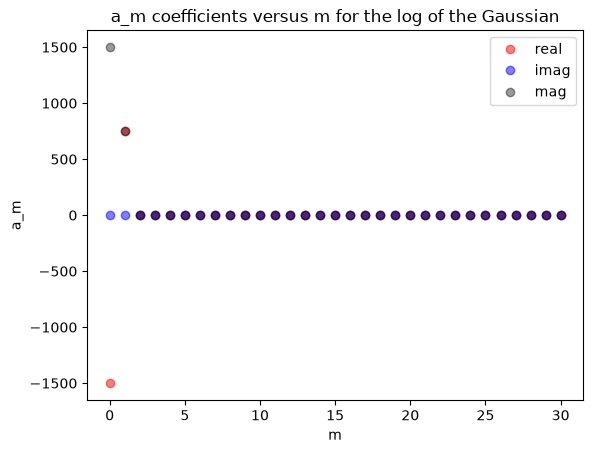

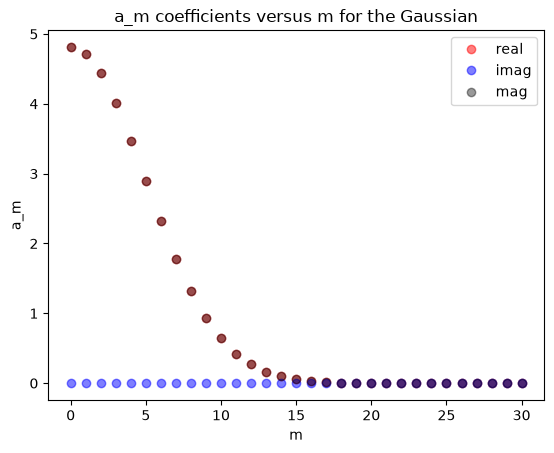

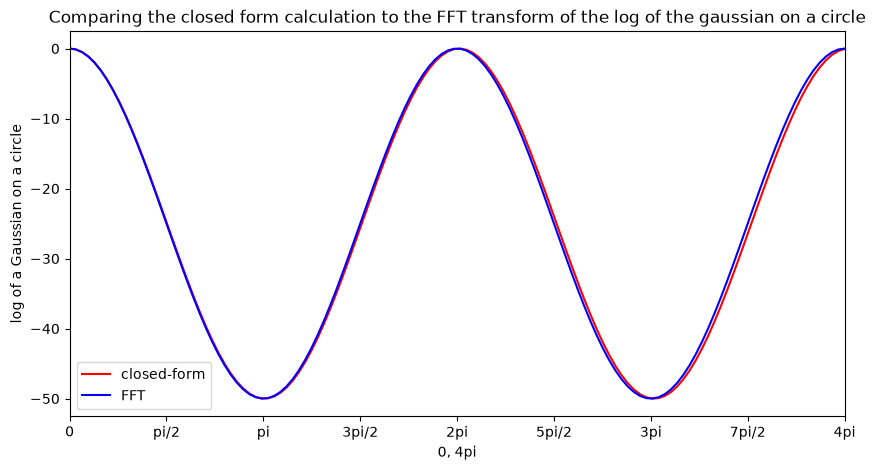

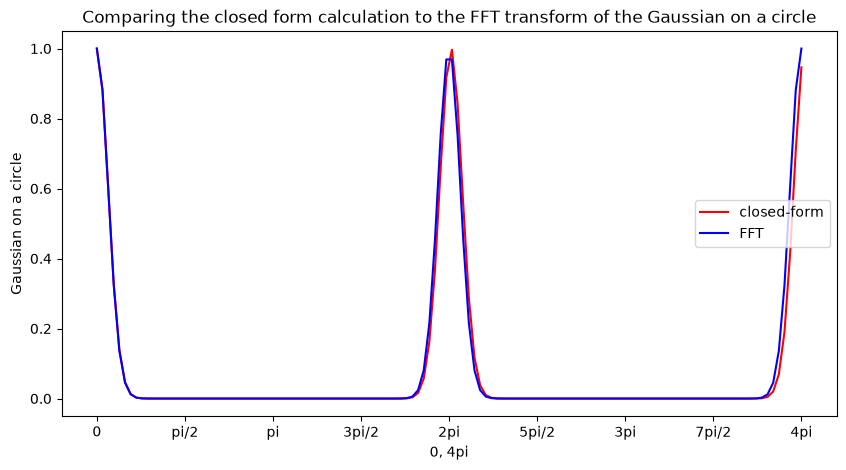

In [8]:
plt.plot(real_coeffs, 'o', color = 'red', alpha=0.5, label='real')
plt.plot(imag_coeffs, 'o', color = 'blue', alpha=0.5, label='imag')
plt.plot(mag_coeffs, 'o', color = 'black', alpha=0.4, label='mag')
plt.ylabel('a_m')
plt.xlabel('m')
plt.title("a_m coefficients versus m for the log of the Gaussian")
plt.legend()
plt.show()

plt.plot(real_g_coeffs, 'o', color = 'red', alpha=0.5, label='real')
plt.plot(imag_g_coeffs, 'o', color = 'blue', alpha=0.5, label='imag') # no imaginary component
plt.plot(mag_g_coeffs, 'o', color = 'black', alpha=0.4, label='mag')
plt.ylabel('a_m')
plt.xlabel('m')
plt.title("a_m coefficients versus m for the Gaussian")
plt.legend()
# plt.semilogy()
plt.show()

x = np.linspace(0, 4 * np.pi, 126)
y1 = log_gaussian_on_circle(phis, phi_mu, sigma)
y2 = f1(x)

plt.figure(figsize=(10, 5))
plt.plot(x, y1, color='red', label='closed-form')
plt.plot(x, y2, color='blue', label='FFT')
plt.xlim(0, 4*np.pi)
plt.xlabel("0, 4pi")
plt.ylabel("log of a Gaussian on a circle")
plt.title("Comparing the closed form calculation to the FFT transform of the log of the gaussian on a circle") 
plt.legend()

ticks = np.linspace(0, 4*np.pi, 9)
labels = ['0', 'pi/2', 'pi', '3pi/2', '2pi', '5pi/2', '3pi', '7pi/2', '4pi']
plt.xticks(ticks, labels)
plt.show()

plt.figure(figsize=(10, 5))
y3 = gaussian_on_circle(phis, phi_mu, sigma)
y4 = f2(x)
plt.plot(x, y3, color='red', label='closed-form')
plt.plot(x, y4, color='blue', label='FFT')
labels = ['0', 'pi/2', 'pi', '3pi/2', '2pi', '5pi/2', '3pi', '7pi/2', '4pi']
plt.xlabel("0, 4pi")
plt.ylabel("Gaussian on a circle")
plt.title("Comparing the closed form calculation to the FFT transform of the Gaussian on a circle") 
plt.legend()


ticks = np.linspace(0, 4*np.pi, 9)
labels = ['0', 'pi/2', 'pi', '3pi/2', '2pi', '5pi/2', '3pi', '7pi/2', '4pi']
plt.xticks(ticks, labels)

plt.show()

Exponentiating the log back into the Gaussian itself, and using FFT to get the Gaussian's Fourier coefficients., and notice that moving the center of the Gaussian phi_mu only adds a phase change.

In [10]:
def exp_coeffs_fft(z, M, N=None):
    if N is None:
        width = np.sqrt(2 * abs(z[1])) + 2 * np.sqrt(2 * abs(z[2]))   
        N = 2 * M + 1 + int(10 * width) + 64
    phi = 2 * np.pi * np.arange(N) / N
    g = eval_log(phi, z)
    gmax = g.max()                                   
    a = np.fft.fft(np.exp(g - gmax)) / N * np.exp(gmax)
    m = np.arange(-M, M + 1)
    return m, a[m % N]  

Integrating the Gaussian over the circle which is the average of N samples times 2pi which is 2pi * a0.

In [12]:
def integral(z, N=64):
    phi = 2 * np.pi * np.arange(N) / N
    return 2 * np.pi * np.exp(eval_log(phi, z)).mean()

Plotting

In [14]:
M = 199                                   # coefficients 
mu = np.array([1.0, 0.0])                 # center the circle at phi = 0

for sigma in [0.5, 0.2, 0.1, 0.05]:
    cov = sigma**2 * np.eye(2)            # isotropic covariance with width sigma
    z = log_coeffs(mu, cov)               # the 3 log coefficients
    m, a = exp_coeffs_fft(z, M)           # coefficients of the Gaussian itself
    keep = m >= 0                         
    plt.plot(m[keep], np.log(np.abs(a[keep] / a[M])**2), label=f"σ = {sigma}")   

plt.axhline(-1, ls=":", color="gray")    
plt.ylim(-75, 2)
plt.xlabel("m")
plt.ylabel("ln(|a_m|² / |a_0|²)")
plt.legend()
plt.show()

TypeError: log_coeffs() takes 1 positional argument but 2 were given

Notice that the shape of our graph is parabolic. It shows us how rapidly the magnitude of the Fourier coefficients shrink with shows us how many terms we would need for precision. It also shows that the width of our gaussian(covariance/sigma) determines how many terms we need on the circle. When sigma is small, the Gaussian is spiked, and we require higher frequencies to avoid missing the spike along the circle. 

Answering the question of evaluating a likelihood in orbit fitting. How many evaluations does an accurate integral requre, when does a spiked Gaussian get missed. 